# 02 – Market data

Maps every holding and benchmark proxy to a Yahoo Finance symbol, checks availability and currency, downloads daily prices, converts them to EUR with ECB reference rates, splices documented proxies before a fund's start date, and stores everything in SQLite.

**Series rules** (in order): 1) the listing actually held, if Yahoo has it (`listing`); 2) the same instrument on another listing (`alt_listing`); 3) a fund on the same or a near-identical index (`proxy_symbol`), used only for dates before the actual series starts.

## Setup

In [1]:
import sqlite3
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

In [2]:
PROCESSED_DIR = Path("../data/processed")
REFERENCE_DIR = Path("../data/reference")
START = "2019-01-01"

HOLDINGS_PATH = PROCESSED_DIR / "holdings.parquet"
SYMBOLS_PATH = REFERENCE_DIR / "yahoo_symbols.csv"
OVERRIDES_PATH = REFERENCE_DIR / "price_overrides.csv"
DB_PATH = PROCESSED_DIR / "portfolio.db"

ECB_CURRENCIES = ["USD", "GBP", "CHF", "CAD", "SEK"]
MAX_FILL_DAYS = 5          # longest gap (holidays) we forward-fill
JUMP_THRESHOLD = 0.40      # daily move that we flag for review
SPIKE_THRESHOLD = 0.15     # move that is flagged if it reverses the next day

assert HOLDINGS_PATH.exists(), "Run notebook 01 first (holdings export)"
assert SYMBOLS_PATH.exists(), f"Mapping not found: {SYMBOLS_PATH.resolve()}"

## Load holdings and symbol mapping

In [3]:
holdings = pd.read_parquet(HOLDINGS_PATH)
symbols = pd.read_csv(SYMBOLS_PATH, keep_default_na=False, na_values=[""])

print(holdings.shape)
print(symbols.shape)
symbols["role"].value_counts()

(55, 30)
(63, 8)


role
holding      55
benchmark     8
Name: count, dtype: int64

In [4]:
holding_tickers = set(symbols.loc[symbols["role"] == "holding", "ticker"])

assert set(holdings["ticker"]) == holding_tickers, "Mapping and holdings do not match"
assert not symbols["ticker"].duplicated().any(), "Duplicate tickers in mapping"
assert symbols["yahoo_symbol"].notna().all(), "Some rows have no Yahoo symbol"
"mapping covers all 55 holdings and 8 benchmarks"

'mapping covers all 55 holdings and 8 benchmarks'

## Series table

One row per series to download: the actual series for every ticker, plus a proxy series where the mapping defines one.

In [5]:
actual_series = symbols[["ticker", "yahoo_symbol", "expected_currency"]].assign(series="actual")
proxy_series = (
    symbols.dropna(subset=["proxy_symbol"])[["ticker", "proxy_symbol", "proxy_currency"]]
    .rename(columns={"proxy_symbol": "yahoo_symbol", "proxy_currency": "expected_currency"})
    .assign(series="proxy")
)
series = pd.concat([actual_series, proxy_series], ignore_index=True)
series = series.rename(columns={"expected_currency": "currency"})

print(series["series"].value_counts())
series[series["series"] == "proxy"]

series
actual    63
proxy      4
Name: count, dtype: int64


,ticker,yahoo_symbol,currency,series
63,GRID,GRID,USD,proxy
64,WENS,WNRG.L,USD,proxy
65,SILV,SIL,USD,proxy
66,EPIN,EPI,USD,proxy


## Availability check

For every series: does Yahoo return data, in which currency, and from which date? The currency must match the mapping exactly, because the EUR conversion relies on it.

In [6]:
def check_symbol(symbol, start=START):
    """Return availability, currency and history length of one Yahoo symbol."""
    ticker = yf.Ticker(symbol)
    try:
        hist = ticker.history(start=start, auto_adjust=False)
    except Exception as exc:
        return {"available": False, "error": str(exc)}
    if hist.empty:
        return {"available": False, "error": "no data"}
    return {
        "available": True,
        "yahoo_currency": ticker.history_metadata.get("currency"),
        "first_date": hist.index.min().date(),
        "n_obs": len(hist),
    }

In [7]:
results = []
for symbol in series["yahoo_symbol"].unique():
    result = check_symbol(symbol)
    result["yahoo_symbol"] = symbol
    results.append(result)
    time.sleep(0.5)

symbol_check = series.merge(pd.DataFrame(results), on="yahoo_symbol", how="left")
symbol_check["currency_match"] = symbol_check["yahoo_currency"] == symbol_check["currency"]

not_available = symbol_check[symbol_check["available"] != True]
currency_issues = symbol_check[(symbol_check["available"] == True) & ~symbol_check["currency_match"]]

print(f"Not available ({len(not_available)}):", list(not_available["yahoo_symbol"]))
print(f"Currency differs from mapping ({len(currency_issues)}):", list(currency_issues["yahoo_symbol"]))

Not available (0): []
Currency differs from mapping (0): []


In [8]:
assert not_available.empty, "Fix unavailable symbols in yahoo_symbols.csv first"
assert currency_issues.empty, "Fix currencies in yahoo_symbols.csv first"

## Download prices

`auto_adjust=False` keeps two series per symbol: `Close` (price only) and `Adj Close` (adjusted for dividends and splits, our total-return series). Yahoo's dividend adjustment uses gross dividends, so it slightly overstates the return of an investor who pays withholding tax.

In [9]:
def download_prices(yahoo_symbols, start=START):
    """Download daily Close and Adj Close for a list of Yahoo symbols."""
    data = yf.download(yahoo_symbols, start=start, auto_adjust=False, progress=False)
    return data["Close"], data["Adj Close"]

In [10]:
yahoo_symbols = sorted(series["yahoo_symbol"].unique())
close_raw, adj_close_raw = download_prices(yahoo_symbols)

print(close_raw.shape)
missing_columns = set(yahoo_symbols) - set(close_raw.columns)
assert not missing_columns, f"Download returned no column for: {missing_columns}"
close_raw.index.min(), close_raw.index.max()

(2025, 66)


(Timestamp('2019-01-02 00:00:00'), Timestamp('2026-10-30 00:00:00'))

## Price overrides

Known data errors are removed before any calculation. Every override is a row in `price_overrides.csv` with a reason, so the correction is documented and reviewable rather than hidden in code. A dropped price becomes `NaN`; the forward-fill in the EUR conversion then carries the last good price.

In [11]:
def apply_overrides(prices, overrides):
    """Set prices to NaN for every (symbol, date range) listed in overrides."""
    prices = prices.copy()
    for _, row in overrides.iterrows():
        mask = (prices.index >= row["start_date"]) & (prices.index <= row["end_date"])
        prices.loc[mask, row["yahoo_symbol"]] = float("nan")
    return prices

In [12]:
overrides = pd.read_csv(OVERRIDES_PATH, parse_dates=["start_date", "end_date"])
assert set(overrides["action"]) <= {"drop"}, "Only 'drop' overrides are supported"

close_raw = apply_overrides(close_raw, overrides)
adj_close_raw = apply_overrides(adj_close_raw, overrides)
overrides[["yahoo_symbol", "start_date", "end_date", "reason"]]

,yahoo_symbol,start_date,end_date,reason
0,WNRG.L,2020-03-17,2020-03-17,Single-day spike of +45% reversed the next day...
1,WREE.L,2024-04-22,2024-04-24,"First days quoted in GBP, later in pence (GBp)..."


## ECB exchange rates

ECB reference rates are quoted as 1 EUR = X units of foreign currency, fixed at 14:15 CET. US closing prices come later in the day, which adds a small timing noise to daily EUR returns of USD positions (negligible at monthly frequency).

In [13]:
def fetch_ecb_rates(currencies, start=START):
    """Download daily ECB reference rates (1 EUR = X currency) as a wide table."""
    key = "+".join(currencies)
    url = (
        f"https://data-api.ecb.europa.eu/service/data/EXR/D.{key}.EUR.SP00.A"
        f"?format=csvdata&startPeriod={start}"
    )
    raw = pd.read_csv(url)
    rates = raw.pivot(index="TIME_PERIOD", columns="CURRENCY", values="OBS_VALUE")
    rates.index = pd.to_datetime(rates.index)
    return rates.sort_index()

In [14]:
fx = fetch_ecb_rates(ECB_CURRENCIES)

assert set(fx.columns) == set(ECB_CURRENCIES), f"Missing currencies: {set(ECB_CURRENCIES) - set(fx.columns)}"
print(fx.shape)
fx.tail(3)

(2006, 5)


CURRENCY,CAD,CHF,GBP,SEK,USD
TIME_PERIOD,,,,,
2026-10-28,1.5638,0.9247,0.83785,11.0560,1.1133
2026-10-29,1.5577,0.9222,0.83578,10.9995,1.1130
2026-10-30,1.5606,0.9194,0.83380,10.9780,1.1172


## Convert to EUR

Steps per series: pence to pounds where needed, forward-fill short gaps (exchange holidays, at most `MAX_FILL_DAYS`), divide by the ECB rate of that day. Forward-filling never fills backwards, so dates before a series starts stay `NaN`.

In [15]:
def to_eur(prices, currency_by_symbol, fx):
    """Convert a wide table of local prices to EUR, column by column."""
    dates = prices.index
    fx_aligned = fx.reindex(dates).ffill(limit=MAX_FILL_DAYS)
    eur = pd.DataFrame(index=dates)
    for symbol in prices.columns:
        local = prices[symbol].ffill(limit=MAX_FILL_DAYS)
        currency = currency_by_symbol[symbol]
        if currency == "GBp":
            local = local / 100
            currency = "GBP"
        if currency == "EUR":
            eur[symbol] = local
        else:
            eur[symbol] = local / fx_aligned[currency]
    return eur

In [16]:
currency_by_symbol = series.drop_duplicates("yahoo_symbol").set_index("yahoo_symbol")["currency"]

close_eur = to_eur(close_raw[yahoo_symbols], currency_by_symbol, fx)
adj_close_eur = to_eur(adj_close_raw[yahoo_symbols], currency_by_symbol, fx)
adj_close_eur.iloc[-1].sort_values().head()

ICHN.AS    4.526495
IKSA.L     5.314178
NXE        7.402435
DAGB.L     8.945191
WENS.L     9.923243
Name: 2026-10-30 00:00:00, dtype: float64

## Data quality: suspicious jumps

A daily move above `JUMP_THRESHOLD` is either a real event or a data error (for example a switch between pounds and pence, or a split that Yahoo did not adjust). Every flagged row must be explained before we use the data.

In [17]:
daily_returns = adj_close_eur.pct_change(fill_method=None)
jumps = daily_returns.stack().dropna()
jumps = jumps[jumps.abs() > JUMP_THRESHOLD]
jumps = jumps.rename("return").reset_index()
jumps.columns = ["date", "yahoo_symbol", "return"]
jumps

,date,yahoo_symbol,return


A second check catches smaller errors: a move above `SPIKE_THRESHOLD` that is largely reversed the next day. Real news rarely reverses within a day; bad prints usually do.

In [18]:
next_day = daily_returns.shift(-1)
spike = (daily_returns.abs() > SPIKE_THRESHOLD) & (daily_returns * next_day < 0) & ((daily_returns + next_day).abs() < 0.5 * daily_returns.abs())
spikes = daily_returns[spike].stack().dropna().rename("return").reset_index()
spikes.columns = ["date", "yahoo_symbol", "return"]
spikes["next_day"] = [next_day.loc[d, s] for d, s in zip(spikes["date"], spikes["yahoo_symbol"])]
spikes

,date,yahoo_symbol,return,next_day
0,2020-03-09,IKSA.L,-0.158692,0.085754
1,2020-03-12,ENB,-0.160573,0.206041
2,2020-03-12,EOG,-0.156522,0.083884
3,2020-03-12,HBM.TO,-0.158185,0.187668
4,2020-03-12,WNRG.L,0.192495,-0.280124
5,2020-03-13,ENB,0.206041,-0.121233
6,2020-03-13,INDO.PA,0.155556,-0.136490
7,2020-03-13,MSFT,0.156158,-0.151440
8,2020-03-13,NXE,0.151604,-0.178125
9,2020-03-13,SIL,-0.160894,0.124669


## Returns per ticker, with proxy splicing

For each ticker we take the daily EUR return of its actual series. For tickers with a proxy, the proxy return is used only for dates **before** the first return of the actual series. We splice returns, not prices, so the level difference between two funds does not create a jump.

In [19]:
def ticker_returns(eur_prices, series):
    """Daily EUR returns per ticker, with proxy returns before the actual series starts."""
    returns = eur_prices.pct_change(fill_method=None)
    out = {}
    source = {}
    for ticker, rows in series.groupby("ticker"):
        actual_symbol = rows.loc[rows["series"] == "actual", "yahoo_symbol"].iloc[0]
        actual = returns[actual_symbol]
        combined = actual.copy()
        used = pd.Series("actual", index=returns.index).where(actual.notna())
        proxy_rows = rows[rows["series"] == "proxy"]
        if not proxy_rows.empty:
            proxy = returns[proxy_rows["yahoo_symbol"].iloc[0]]
            before_start = returns.index < actual.first_valid_index()
            combined[before_start] = proxy[before_start]
            used[before_start & proxy.notna()] = "proxy"
        out[ticker] = combined
        source[ticker] = used
    return pd.DataFrame(out), pd.DataFrame(source)

In [20]:
returns_total, returns_source = ticker_returns(adj_close_eur, series)
returns_price, _ = ticker_returns(close_eur, series)

print(returns_total.shape)
returns_source.apply(pd.Series.value_counts).T.loc[["EPIN", "SILV", "GRID", "WENS"]]

(2025, 63)


,actual,proxy
EPIN,177.0,1847.0
SILV,1146.0,878.0
GRID,1174.0,850.0
WENS,1120.0,904.0


## Coverage

Coverage on a date = share of the current portfolio weight that has a return on that date. This decides which analysis windows are defensible.

In [21]:
weights = holdings.set_index("ticker")["weight_in_portfolio"]
coverage = returns_total[weights.index].notna().mul(weights, axis=1).sum(axis=1)

key_dates = ["2020-02-19", "2022-01-03", "2023-12-29", "2024-12-31", "2025-09-30"]
coverage.asof(pd.to_datetime(key_dates)).round(3)

2020-02-19    0.912
2022-01-03    0.929
2023-12-29    0.945
2024-12-31    0.971
2025-09-30    1.000
dtype: float64

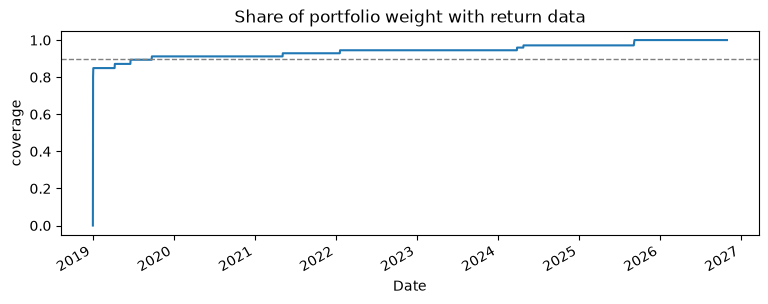

In [22]:
ax = coverage.plot(figsize=(9, 3), title="Share of portfolio weight with return data")
ax.axhline(0.9, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("coverage")
plt.show()

## Store in SQLite

Long format (one row per date and ticker) is the natural shape for SQL. Wide returns are also saved as Parquet for fast use in notebook 04.

In [23]:
def to_long(wide, value_name):
    """Turn a wide date x ticker table into long format without empty rows."""
    long = wide.stack().dropna().rename(value_name).reset_index()
    long.columns = ["date", "ticker", value_name]
    return long

In [24]:
returns_long = (
    to_long(returns_total, "return_total")
    .merge(to_long(returns_price, "return_price"), on=["date", "ticker"], how="left")
    .merge(to_long(returns_source, "source"), on=["date", "ticker"], how="left")
)
prices_long = (
    to_long(close_raw[yahoo_symbols], "close")
    .merge(to_long(adj_close_raw[yahoo_symbols], "adj_close"), on=["date", "ticker"], how="left")
    .rename(columns={"ticker": "yahoo_symbol"})
)
fx_long = to_long(fx, "eur_rate").rename(columns={"ticker": "currency"})

with sqlite3.connect(DB_PATH) as con:
    holdings.to_sql("holdings", con, if_exists="replace", index=False)
    symbols.to_sql("symbols", con, if_exists="replace", index=False)
    prices_long.to_sql("prices_local", con, if_exists="replace", index=False)
    fx_long.to_sql("fx_ecb", con, if_exists="replace", index=False)
    returns_long.to_sql("returns_eur", con, if_exists="replace", index=False)

returns_total.to_parquet(PROCESSED_DIR / "returns_total_eur.parquet")
returns_price.to_parquet(PROCESSED_DIR / "returns_price_eur.parquet")

with sqlite3.connect(DB_PATH) as con:
    print(pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", con))
    print(pd.read_sql("SELECT COUNT(*) AS n_rows FROM returns_eur", con))

           name
0      holdings
1       symbols
2  prices_local
3        fx_ecb
4   returns_eur
   n_rows
0  118000
